In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

In [3]:
df = pd.read_csv(next(iter(uploaded.keys())))

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Outcome"].value_counts())

Dataset shape: (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [7]:
X = df.drop("Outcome", axis=1)

y = df["Outcome"]

print("Input data:")
print(X.head())

print("\nTarget:")
print(y.head())

Input data:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Target:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [8]:
X = pd.get_dummies(X, drop_first=True)

print(X.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [10]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [11]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 1 0
 0 1 0 0 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 1 0 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0
 1 1 1 1 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1
 0 0 0 0 1 0]

Predicted values:
[1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 1 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 0 0
 0 1 0 0 0 0 1 0 0 0 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 0 1 0 1 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 0 1 0 0
 1 1 0 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 1 0]


In [12]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[85 15]
 [22 32]]


In [13]:
TN, FP, FN, TP = cm.ravel()

print("True Positive (TP):", TP)
print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)

True Positive (TP): 32
True Negative (TN): 85
False Positive (FP): 15
False Negative (FN): 22


In [14]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 75.97 %


In [15]:
precision = precision_score(y_test, y_pred)

print("Precision:", round(precision * 100, 2), "%")

Precision: 68.09 %


In [16]:
recall = recall_score(y_test, y_pred)

print("Recall:", round(recall * 100, 2), "%")

Recall: 59.26 %


In [17]:
f1 = f1_score(y_test, y_pred)

print("F1-Score:", round(f1 * 100, 2), "%")

F1-Score: 63.37 %


In [18]:
print("===== DIABETES MODEL RESULTS =====")

print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

print("--------------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")

===== DIABETES MODEL RESULTS =====
TP: 32
TN: 85
FP: 15
FN: 22
--------------------------------
Accuracy: 75.97 %
Precision: 68.09 %
Recall: 59.26 %
F1-Score: 63.37 %


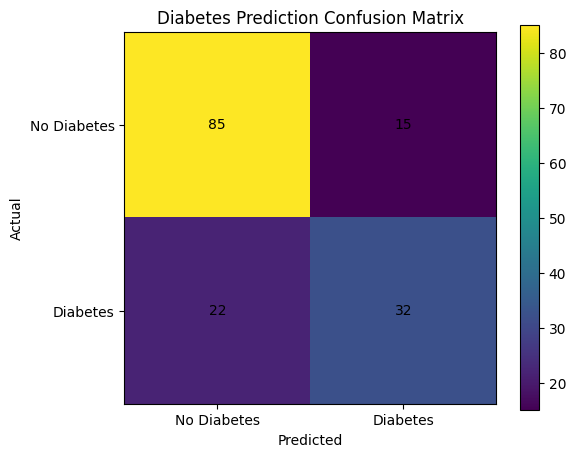

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Diabetes Prediction Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.yticks([0, 1], ["No Diabetes", "Diabetes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [21]:
X = df.drop("Outcome", axis=1)

y = df["Outcome"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Target values:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [22]:
X = pd.get_dummies(X, drop_first=True)

print(X.head())

print("\nEncoded column names:")
print(X.columns.tolist())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Encoded column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [24]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [25]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 1 0
 0 1 0 0 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 1 0 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0
 1 1 1 1 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1
 0 0 0 0 1 0]

Predicted values:
[1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 1 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 1 0 0
 0 1 0 0 0 0 1 0 0 0 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 0 1 0 1 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 0 1 0 0
 1 1 0 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 1 0]


In [26]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[85 15]
 [22 32]]


In [27]:
TN, FP, FN, TP = cm.ravel()

print("True Positive (TP):", TP)
print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)

True Positive (TP): 32
True Negative (TN): 85
False Positive (FP): 15
False Negative (FN): 22


In [28]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 75.97 %


In [29]:
precision = precision_score(y_test, y_pred)

print("Precision:", round(precision * 100, 2), "%")

Precision: 68.09 %


In [30]:
recall = recall_score(y_test, y_pred)

print("Recall:", round(recall * 100, 2), "%")

Recall: 59.26 %


In [31]:
f1 = f1_score(y_test, y_pred)

print("F1-Score:", round(f1 * 100, 2), "%")

F1-Score: 63.37 %


In [32]:
print("===== DIABETES PREDICTION RESULTS =====")

print("True Positive (TP):", TP)
print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)

print("--------------------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")

===== DIABETES PREDICTION RESULTS =====
True Positive (TP): 32
True Negative (TN): 85
False Positive (FP): 15
False Negative (FN): 22
--------------------------------------
Accuracy: 75.97 %
Precision: 68.09 %
Recall: 59.26 %
F1-Score: 63.37 %


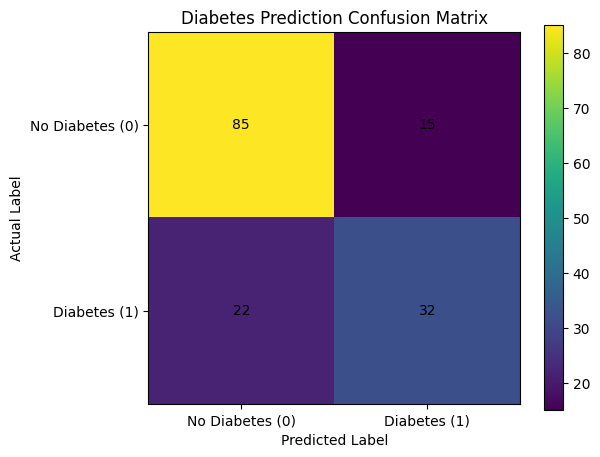

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Diabetes Prediction Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["No Diabetes (0)", "Diabetes (1)"])
plt.yticks([0, 1], ["No Diabetes (0)", "Diabetes (1)"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [34]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.85      0.82       100
           1       0.68      0.59      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.73       154
weighted avg       0.75      0.76      0.76       154

